In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

In [ ]:
df = pd.read_csv('/content/battery_cycle_level_dataset_CLEAN_FINAL.csv')

In [ ]:
df['SoH'] = df['capacity'] / 2.0

In [ ]:
max_cycles_per_battery = df.groupby('battery_id')['cycle'].transform('max')
df['RUL'] = max_cycles_per_battery - df['cycle']

In [ ]:
train_df = df[df['battery_id'] != 'B0018']
test_df = df[df['battery_id'] == 'B0018']

In [ ]:
features = ['cycle', 'voltage', 'temperature', 'capacity']
targets = ['SoH', 'RUL']

X_train = train_df[features]
y_train = train_df[targets]

X_test = test_df[features]
y_test = test_df[targets]

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, n_jobs=-1, random_state=42)

In [ ]:
predictions = rf_model.predict(X_test)

In [ ]:
soh_pred = predictions[:, 0]
rul_pred = predictions[:, 1]

# Calculate Mean Absolute Error
mae_soh = mean_absolute_error(y_test['SoH'], soh_pred)
mae_rul = mean_absolute_error(y_test['RUL'], rul_pred)

# Extract Feature Importances
importances = rf_model.feature_importances_
feature_importance_dict = dict(zip(features, importances))


In [ ]:
print("--- Evaluation on Unseen Test Battery: B0018 ---")
print(f"SoH Mean Absolute Error: {mae_soh:.4f}")
print(f"RUL Mean Absolute Error: {mae_rul:.2f} cycles\n")

print("--- Feature Importance ---")
print(f"cycle: {feature_importance_dict['cycle']:.4f}")
print(f"voltage: {feature_importance_dict['voltage']:.4f}")
print(f"temperature: {feature_importance_dict['temperature']:.4f}")
print(f"capacity: {feature_importance_dict['capacity']:.4f}")

--- Evaluation on Unseen Test Battery: B0018 ---
SoH Mean Absolute Error: 0.0145
RUL Mean Absolute Error: 12.55 cycles

--- Feature Importance ---
cycle: 0.1391
voltage: 0.6492
temperature: 0.0772
capacity: 0.1345


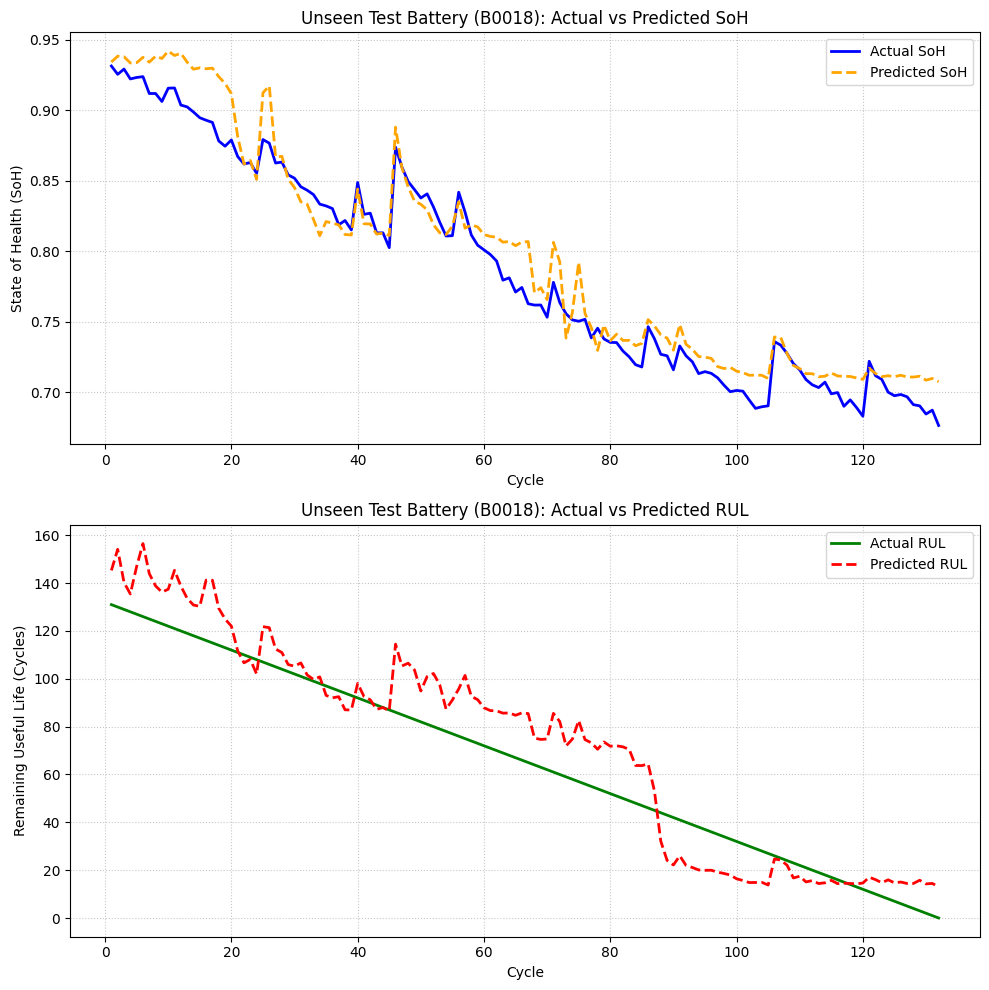

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

# --- Plot 1: State of Health (SoH) ---
ax1.plot(test_df['cycle'], y_test['SoH'], label='Actual SoH', color='blue', linewidth=2)
ax1.plot(test_df['cycle'], soh_pred, label='Predicted SoH', color='orange', linestyle='--', linewidth=2)
ax1.set_title('Unseen Test Battery (B0018): Actual vs Predicted SoH')
ax1.set_xlabel('Cycle')
ax1.set_ylabel('State of Health (SoH)')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.7)

# --- Plot 2: Remaining Useful Life (RUL) ---
ax2.plot(test_df['cycle'], y_test['RUL'], label='Actual RUL', color='green', linewidth=2)
ax2.plot(test_df['cycle'], rul_pred, label='Predicted RUL', color='red', linestyle='--', linewidth=2)
ax2.set_title('Unseen Test Battery (B0018): Actual vs Predicted RUL')
ax2.set_xlabel('Cycle')
ax2.set_ylabel('Remaining Useful Life (Cycles)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.7)

# Adjust layout to prevent overlap and display the plots
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, median_absolute_error, max_error)

# ------------------------------------------------------------
# 1. Full metrics (accuracy + correlation)
# ------------------------------------------------------------
def full_metrics(y_true, y_pred, name):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mae   = mean_absolute_error(y_true, y_pred)
    rmse  = np.sqrt(mean_squared_error(y_true, y_pred))
    medae = median_absolute_error(y_true, y_pred)
    maxe  = max_error(y_true, y_pred)
    r2    = r2_score(y_true, y_pred)
    mape  = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-8, None))) * 100
    pear, _  = pearsonr(y_true, y_pred)
    spear, _ = spearmanr(y_true, y_pred)
    bias  = np.mean(y_pred - y_true)  # +ve = over-prediction
    return pd.Series({
        'MAE': mae, 'RMSE': rmse, 'MedAE': medae, 'MaxError': maxe,
        'R2': r2, 'MAPE_%': mape, 'Pearson_r': pear,
        'Spearman_rho': spear, 'Bias(mean error)': bias
    }, name=name)

results = pd.DataFrame([
    full_metrics(y_test['SoH'], soh_pred, 'SoH'),
    full_metrics(y_test['RUL'], rul_pred, 'RUL'),
])
print("=== Test metrics on B0018 ===")
print(results.round(4).T)

=== Test metrics on B0018 ===
                     SoH           RUL
MAE               0.0145  1.255230e+01
RMSE              0.0182  1.460750e+01
MedAE             0.0118  1.337960e+01
MaxError          0.0456  3.053440e+01
R2                0.9431  8.530000e-01
MAPE_%            1.8395  9.874047e+08
Pearson_r         0.9823  9.640000e-01
Spearman_rho      0.9901  9.744000e-01
Bias(mean error)  0.0109  7.134600e+00


In [ ]:
# ------------------------------------------------------------
# 2. Baseline comparison
# ------------------------------------------------------------
baselines = {
    'Mean predictor': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
}
rows = []
for name, m in baselines.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({'Model': name,
                 'SoH_MAE': mean_absolute_error(y_test['SoH'], p[:, 0]),
                 'SoH_R2':  r2_score(y_test['SoH'], p[:, 0]),
                 'RUL_MAE': mean_absolute_error(y_test['RUL'], p[:, 1]),
                 'RUL_R2':  r2_score(y_test['RUL'], p[:, 1])})
rows.append({'Model': 'Random Forest',
             'SoH_MAE': mean_absolute_error(y_test['SoH'], soh_pred),
             'SoH_R2':  r2_score(y_test['SoH'], soh_pred),
             'RUL_MAE': mean_absolute_error(y_test['RUL'], rul_pred),
             'RUL_R2':  r2_score(y_test['RUL'], rul_pred)})
print("\n=== Baseline comparison ===")
print(pd.DataFrame(rows).round(4).to_string(index=False))


=== Baseline comparison ===
            Model  SoH_MAE  SoH_R2  RUL_MAE  RUL_R2
   Mean predictor   0.0695 -0.2623  34.1798 -0.1074
Linear Regression   0.0000  1.0000  18.6470  0.6657
    Random Forest   0.0145  0.9431  12.5523  0.8530


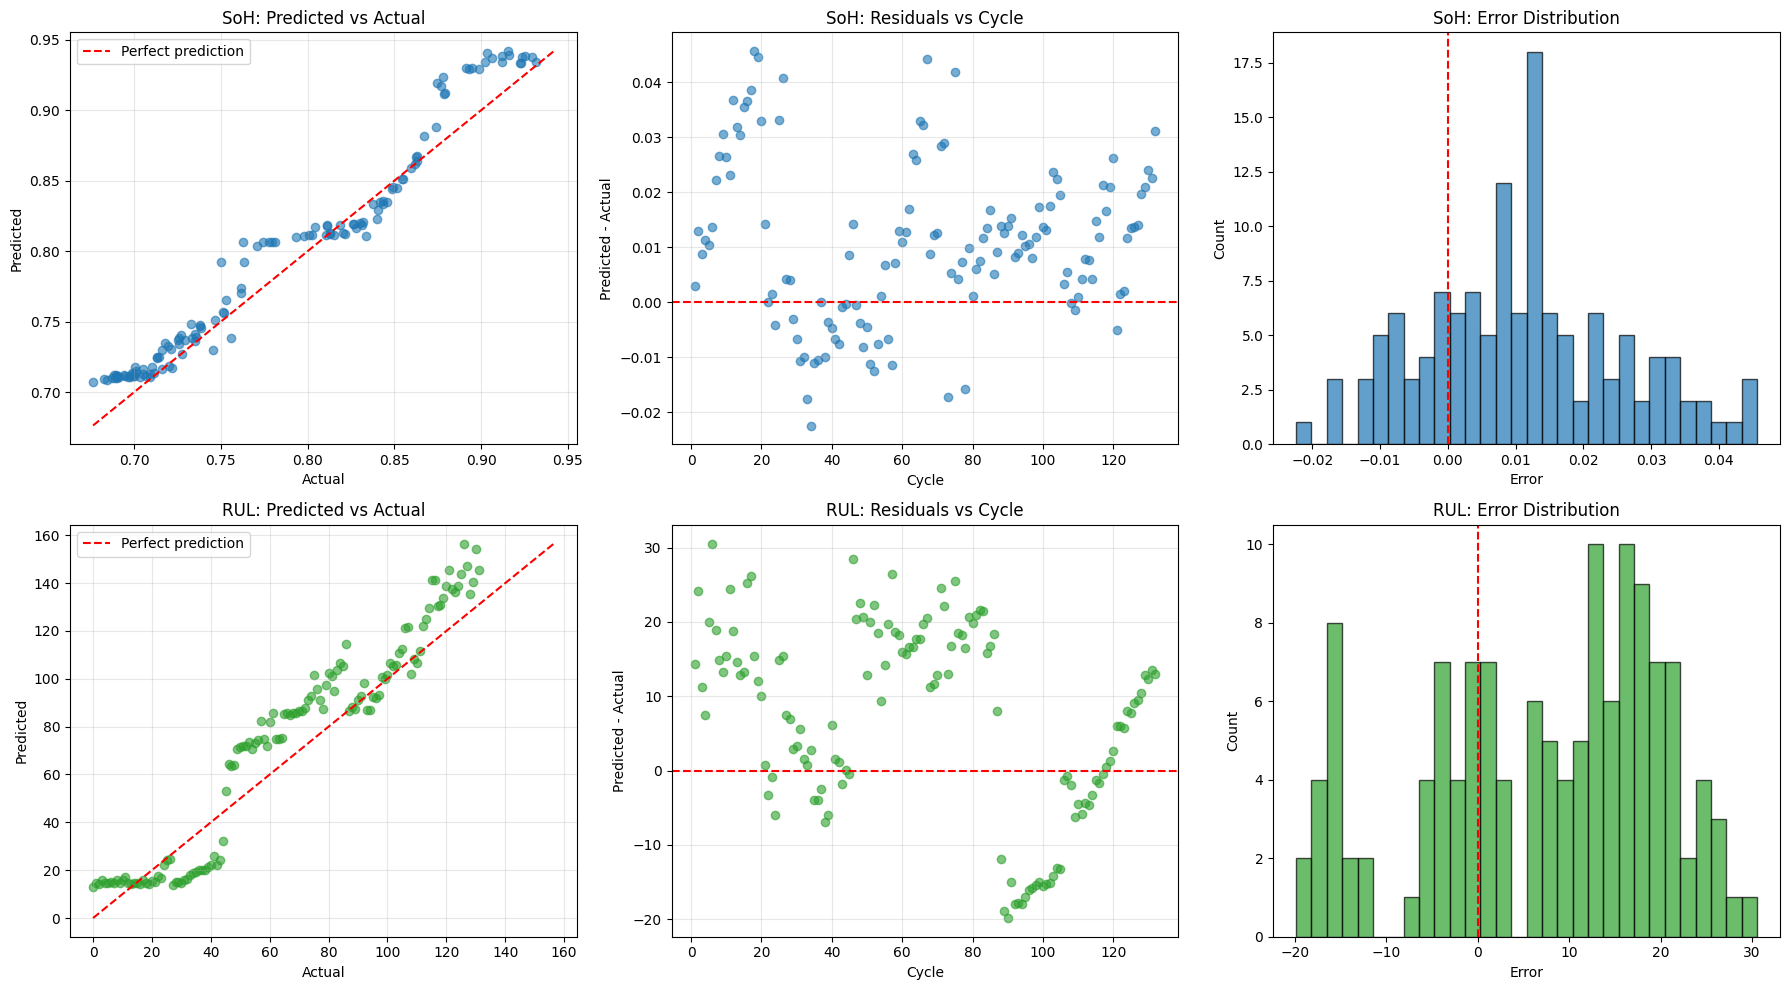

In [ ]:
# ------------------------------------------------------------
# 3. Diagnostic plots: scatter, residuals, error histogram
# ------------------------------------------------------------
soh_res = soh_pred - y_test['SoH'].values
rul_res = rul_pred - y_test['RUL'].values

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for row, (name, yt, yp, res, c) in enumerate([
        ('SoH', y_test['SoH'].values, soh_pred, soh_res, 'tab:blue'),
        ('RUL', y_test['RUL'].values, rul_pred, rul_res, 'tab:green')]):
    # Predicted vs Actual
    ax = axes[row, 0]
    ax.scatter(yt, yp, alpha=0.6, color=c)
    lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    ax.plot(lims, lims, 'r--', label='Perfect prediction')
    ax.set_title(f'{name}: Predicted vs Actual')
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted'); ax.legend(); ax.grid(alpha=0.3)
    # Residuals vs cycle
    ax = axes[row, 1]
    ax.scatter(test_df['cycle'], res, alpha=0.6, color=c)
    ax.axhline(0, color='r', linestyle='--')
    ax.set_title(f'{name}: Residuals vs Cycle')
    ax.set_xlabel('Cycle'); ax.set_ylabel('Predicted - Actual'); ax.grid(alpha=0.3)
    # Error distribution
    ax = axes[row, 2]
    ax.hist(res, bins=30, color=c, alpha=0.7, edgecolor='k')
    ax.axvline(0, color='r', linestyle='--')
    ax.set_title(f'{name}: Error Distribution')
    ax.set_xlabel('Error'); ax.set_ylabel('Count')
plt.tight_layout(); plt.show()


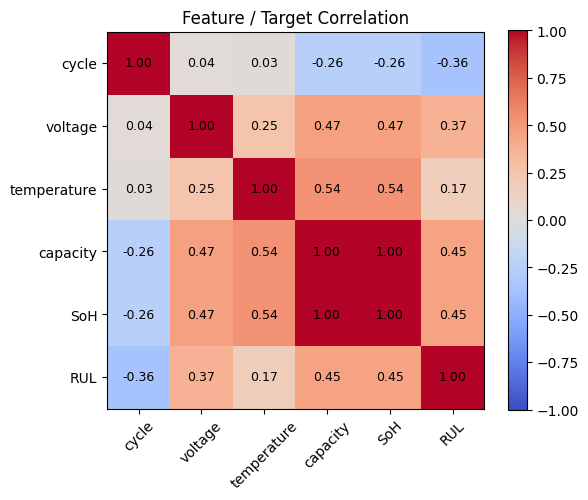

In [ ]:
# ------------------------------------------------------------
# 4. Correlation heatmap (features + targets)
# ------------------------------------------------------------
corr = df[features + targets].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
plt.colorbar(im); ax.set_title('Feature / Target Correlation'); plt.tight_layout(); plt.show()

In [ ]:
# ------------------------------------------------------------
# 5. Error vs life-stage (RUL early vs late cycles)
# ------------------------------------------------------------
stage = pd.cut(test_df['cycle'] / test_df['cycle'].max(),
               bins=[0, 0.33, 0.66, 1.0], labels=['Early', 'Mid', 'Late'])
stage_df = pd.DataFrame({'stage': stage.values,
                         'SoH_AE': np.abs(soh_res), 'RUL_AE': np.abs(rul_res)})
print("\n=== MAE by life stage ===")
print(stage_df.groupby('stage', observed=True).mean().round(4))


=== MAE by life stage ===
       SoH_AE   RUL_AE
stage                 
Early  0.0174  10.4533
Mid    0.0133  17.4420
Late   0.0129   9.7770


In [ ]:
# ------------------------------------------------------------
# 6. Leave-One-Battery-Out CV (sabse reliable generalization test)
# ------------------------------------------------------------
logo_rows = []
for b in df['battery_id'].unique():
    tr, te = df[df['battery_id'] != b], df[df['battery_id'] == b]
    m = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    m.fit(tr[features], tr[targets])
    p = m.predict(te[features])
    logo_rows.append({'Held-out battery': b,
                      'SoH_MAE': mean_absolute_error(te['SoH'], p[:, 0]),
                      'SoH_R2':  r2_score(te['SoH'], p[:, 0]),
                      'RUL_MAE': mean_absolute_error(te['RUL'], p[:, 1]),
                      'RUL_R2':  r2_score(te['RUL'], p[:, 1])})
logo = pd.DataFrame(logo_rows)
print("\n=== Leave-One-Battery-Out CV ===")
print(logo.round(4).to_string(index=False))
print("\nMean ± Std:")
print(logo.drop(columns='Held-out battery').agg(['mean', 'std']).round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, Unde


=== Leave-One-Battery-Out CV ===
Held-out battery  SoH_MAE     SoH_R2  RUL_MAE    RUL_R2
           B0005   0.0261     0.8442  13.8846    0.8833
           B0006   0.0293     0.9213  23.6025    0.6257
           B0007   0.0192     0.9137   7.1425    0.9663
           B0018   0.0145     0.9431  12.5523    0.8530
           B0025   0.1363   -22.9445  11.4640   -7.6412
           B0026   0.0661    -0.9482  19.0257  -16.6198
           B0027   0.0646    -2.7266   4.8712    0.2254
           B0028   0.1044    -4.9105 119.1526 -216.6315
           B0029   0.0133     0.6656   1.5251    0.9345
           B0030   0.0245    -0.1264   2.9999    0.8780
           B0031   0.0193    -1.8461  23.2438  -10.1323
           B0032   0.0265    -0.6964   3.8771    0.7579
           B0033   0.6353  -198.9367  43.9767    0.0540
           B0034   0.0129        NaN  14.9348       NaN
           B0036   0.0155        NaN  25.9666       NaN
           B0038   0.0483        NaN  14.1393       NaN
           B00

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


In [ ]:
# ------------------------------------------------------------
# 7. Ablation: feature hatake dekho (leakage check)
# ------------------------------------------------------------
def run_ablation(feats):
    m = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    m.fit(train_df[feats], train_df[targets])
    p = m.predict(test_df[feats])
    return {'Features': ', '.join(feats),
            'SoH_MAE': mean_absolute_error(y_test['SoH'], p[:, 0]),
            'SoH_R2':  r2_score(y_test['SoH'], p[:, 0]),
            'RUL_MAE': mean_absolute_error(y_test['RUL'], p[:, 1]),
            'RUL_R2':  r2_score(y_test['RUL'], p[:, 1])}

ablation = pd.DataFrame([
    run_ablation(features),
    run_ablation(['cycle', 'voltage', 'temperature']),   # without capacity
    run_ablation(['voltage', 'temperature', 'capacity']),# without cycle
    run_ablation(['voltage', 'temperature']),            # only sensor features
])
print("\n=== Ablation study ===")
print(ablation.round(4).to_string(index=False))


=== Ablation study ===
                             Features  SoH_MAE  SoH_R2  RUL_MAE  RUL_R2
cycle, voltage, temperature, capacity   0.0145  0.9431  12.5523  0.8530
          cycle, voltage, temperature   0.0388  0.6722  17.4999  0.7274
       voltage, temperature, capacity   0.0103  0.9678  14.1073  0.7465
                 voltage, temperature   0.0567  0.3096  37.8886 -0.5056
